# 03 — Model Building & Evaluation

**Phase 5** (see `CONTINUITY.md`). The training code lives in `src/train.py` (run `python -m src.train`, ~3 min). This notebook presents its results and checks that the saved model reloads and predicts.

Setup used for every model: `Pipeline(preprocessor → model)` with `class_weight='balanced'` (Phase 4 decision), 5-fold stratified CV on the **training set only**; the test set is touched exactly once, at the end.

In [1]:
import json, sys
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data_prep import clean, split
from src.load_data import load_raw

def show(png, width=11):
    img = plt.imread(ROOT / "reports" / "figures" / png)
    h, w = img.shape[:2]
    fig, ax = plt.subplots(figsize=(width, width * h / w)); ax.imshow(img); ax.axis("off"); plt.show()

metrics = json.loads((ROOT / "reports" / "model_metrics.json").read_text())

## 5.1–5.3 Baseline + four models, 5-fold cross-validation
XGBoost and LightGBM are added automatically by `src/train.py` when installed (`pip install xgboost lightgbm`).

               model  recall  precision    f1  roc_auc  roc_auc_std
 Logistic Regression   0.803      0.518 0.629    0.846        0.012
       Random Forest   0.767      0.539 0.633    0.845        0.010
HistGradientBoosting   0.731      0.546 0.625    0.837        0.009
       Decision Tree   0.787      0.502 0.613    0.825        0.010


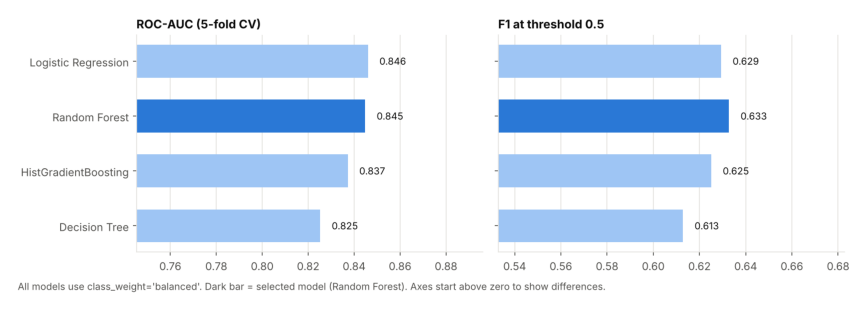

In [2]:
comp = pd.read_csv(ROOT / "reports" / "model_comparison.csv")
print(comp[["model", "recall", "precision", "f1", "roc_auc", "roc_auc_std"]].round(3).to_string(index=False))
show("08_model_comparison.png")

Logistic Regression (the baseline) and Random Forest are effectively tied on ROC-AUC (~0.846); the single Decision Tree is clearly weakest. Differences between the top models are within one standard deviation across folds — this dataset's signal is largely captured by a linear model.

## 5.5 Tuning the top two + the decision threshold

In [3]:
tuned = pd.read_csv(ROOT / "reports" / "tuning_results.csv")
print(tuned.round(4).to_string(index=False))
print(f"\nSelected: {metrics['selected_model']}")
print(f"Engineered features re-check (Phase 4 follow-up): CV ROC-AUC {metrics['engineered_features_cv_roc_auc']} "
      f"vs {tuned.cv_roc_auc_tuned.max():.4f} without -> no meaningful gain, keep 40 base features")
print(f"\nThreshold rule: highest threshold whose out-of-fold recall >= {metrics['target_recall']:.0%}")
print(f"Chosen threshold: {metrics['threshold']}  |  out-of-fold: {metrics['out_of_fold']}")

              model  cv_roc_auc_tuned                                                                            best_params
      Random Forest            0.8486 {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 16, 'n_estimators': 306}
Logistic Regression            0.8462                                                                         {'C': 56.6985}

Selected: Random Forest
Engineered features re-check (Phase 4 follow-up): CV ROC-AUC 0.8487 vs 0.8486 without -> no meaningful gain, keep 40 base features

Threshold rule: highest threshold whose out-of-fold recall >= 80%
Chosen threshold: 0.4903  |  out-of-fold: {'oof_recall': 0.8, 'oof_precision': 0.5193, 'oof_f1': 0.6298, 'oof_roc_auc': 0.8476}


## 5.4 Final evaluation on the held-out test set (1,409 customers)

             threshold  recall  precision     f1  accuracy   tn   fp  fn   tp
chosen            0.49   0.799      0.516  0.627     0.748  755  280  75  299
default 0.5       0.50   0.797      0.517  0.627     0.749  757  278  76  298

Test ROC-AUC: 0.845


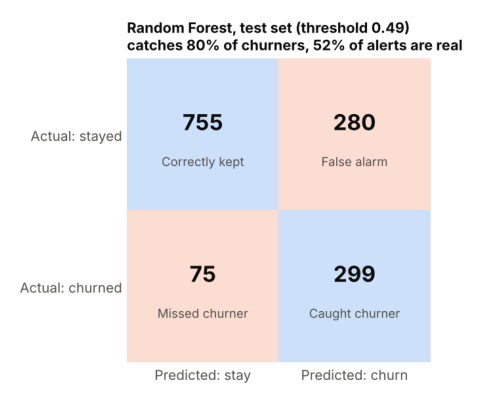

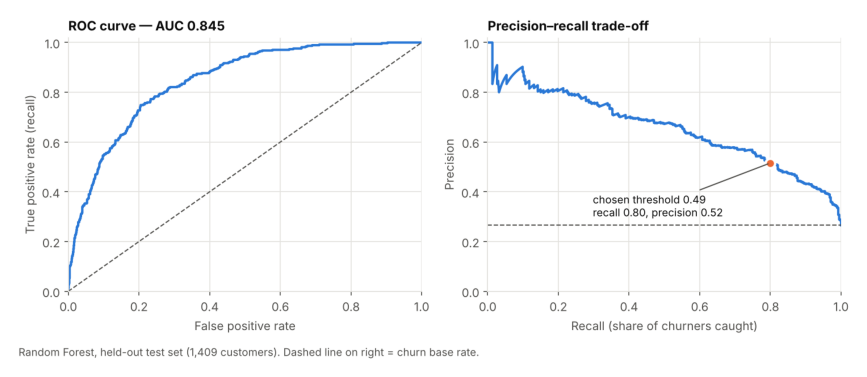

In [4]:
t = metrics["test"]
rows = []
for label in ("tuned_threshold", "default_0.5"):
    m = t[label]
    rows.append({"threshold": m["threshold"], "recall": m["recall"], "precision": m["precision"],
                 "f1": m["f1"], "accuracy": m["accuracy"], **m["confusion"]})
print(pd.DataFrame(rows, index=["chosen", "default 0.5"]).round(3).to_string())
print(f"\nTest ROC-AUC: {t['roc_auc']:.3f}")
show("09_confusion_matrix.png", width=6)
show("10_roc_pr_curves.png")

**Reading the result:** out of 374 customers who actually churned in the test set, the model flags **299 (80%)**. About half of all flagged customers really churn (precision 0.52) — roughly 2× better than contacting customers at random (base rate 26.5%). Test-set numbers match the cross-validation estimates closely, so the model is not overfitting.

The threshold is a business choice: raising it sends fewer false alarms but misses more churners. The precision–recall curve above shows the full trade-off.

## 5.6 Saved model reloads and predicts

In [5]:
bundle = joblib.load(ROOT / "models" / "churn_model.pkl")
pipe, threshold = bundle["pipeline"], bundle["threshold"]
print("Loaded:", bundle["model_name"], "| trained", bundle["trained_on"], "| threshold", round(threshold, 3))

_, X_test, _, y_test = split(clean(load_raw()))
sample = X_test.head(5)
proba = pipe.predict_proba(sample)[:, 1]
out = sample[["tenure", "Contract", "InternetService", "PaymentMethod", "MonthlyCharges"]].copy()
out["churn_probability"] = proba.round(3)
out["flag"] = ["AT RISK" if p >= threshold else "ok" for p in proba]
out["actual"] = y_test.head(5).map({1: "churned", 0: "stayed"}).values
print(out.to_string())

Loaded: Random Forest | trained 2026-11-05 | threshold 0.49
      tenure        Contract InternetService            PaymentMethod  MonthlyCharges  churn_probability     flag  actual
437       72        Two year     Fiber optic  Credit card (automatic)          114.05              0.060       ok  stayed
2280       8  Month-to-month     Fiber optic  Credit card (automatic)          100.15              0.822  AT RISK  stayed
2235      41        One year             DSL  Credit card (automatic)           78.35              0.178       ok  stayed
4460      18  Month-to-month     Fiber optic         Electronic check           78.20              0.603  AT RISK  stayed
3761      72        Two year             DSL  Credit card (automatic)           82.65              0.059       ok  stayed
